In [1]:
# A recommendation engine suggests articles a reader is
# likely to enjoy based on their reading history.
# We use content-based filtering which means we compare
# article content directly using TF-IDF vectors and
# cosine similarity. This is how most news recommendation
# systems work at their core before adding more complexity.
# This mirrors Upscore's Engage product.

print("Starting article recommendation notebook...")

Starting article recommendation notebook...


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")
print("Libraries imported!")

Libraries imported!


In [3]:
# We load the cleaned news data from notebook 01
# and the reader profiles we created in notebook 03.
# We also reload the TF-IDF vectorizer from notebook 02
# so we use consistent text representations throughout.

df_news = pd.read_csv("../data/processed/news_clean.csv")
df_readers = pd.read_csv("../data/processed/readers.csv")

with open("../data/processed/tfidf_vectorizer.pkl", "rb") as f:
    tfidf = pickle.load(f)

with open("../data/processed/churn_model.pkl", "rb") as f:
    churn_model = pickle.load(f)

with open("../data/processed/churn_scaler.pkl", "rb") as f:
    scaler = pickle.load(f)

print(f"News articles loaded : {len(df_news):,}")
print(f"Reader profiles loaded: {len(df_readers):,}")

News articles loaded : 422,419
Reader profiles loaded: 5,000


In [4]:
# We work with a sample of 5000 articles for speed.
# In a real system this would run on the full dataset
# using approximate nearest neighbour search which is
# much faster than computing all pairwise similarities.

import re

def clean_title(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_articles = df_news.sample(5000, random_state=42).reset_index(drop=True)
df_articles["title_clean"] = df_articles["title"].apply(clean_title)

print(f"Working with {len(df_articles):,} articles")
print()
print("Category breakdown:")
print(df_articles["category_name"].value_counts())

Working with 5,000 articles

Category breakdown:
category_name
Entertainment     1819
Business          1389
Science & Tech    1307
Health             485
Name: count, dtype: int64


In [5]:
# We build a TF-IDF matrix for all 5000 articles.
# Each row is one article, each column is one word.
# The value in each cell tells us how important
# that word is for that article.
# We create a fresh vectorizer here rather than reusing
# the one from notebook 02 because we want it fitted
# specifically on these 5000 articles for better similarity.

rec_tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

tfidf_matrix = rec_tfidf.fit_transform(df_articles["title_clean"])

print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
print(f"Rows = articles, Columns = words")

TF-IDF matrix shape: (5000, 5000)
Rows = articles, Columns = words


In [6]:
# Cosine similarity measures how similar two articles are
# based on the angle between their TF-IDF vectors.
# A score of 1.0 means identical, 0.0 means completely different.
# We compute this for all pairs of articles at once.
# This is the core of content-based recommendation.

print("Computing similarity matrix...")

similarity_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Each cell = similarity between two articles")
print()

# Show a quick example
idx_a = 0
idx_b = 1
print(f"Article A: {df_articles['title'].iloc[idx_a]}")
print(f"Article B: {df_articles['title'].iloc[idx_b]}")
print(f"Similarity: {similarity_matrix[idx_a, idx_b]:.4f}")

Computing similarity matrix...
Similarity matrix shape: (5000, 5000)
Each cell = similarity between two articles

Article A: Only 2 people allowed in the delivery room: Pregger Mila Kunis on childbirth
Article B: A wealth of info, a welter of questions
Similarity: 0.0000


In [7]:
# The recommender takes an article title, finds it in
# our dataset, then returns the most similar articles
# based on cosine similarity scores.
# In a real system we would also filter by recency,
# personalise by reader history, and apply business rules
# like not recommending paywalled content to free readers.

def recommend_articles(title, n=5):
    """
    Given an article title return the n most similar articles.
    """

    # Find the article index in our dataset
    matches = df_articles[df_articles["title"] == title]

    if len(matches) == 0:
        print(f"Article not found: {title}")
        return None

    idx = matches.index[0]

    # Get similarity scores for this article vs all others
    sim_scores = list(enumerate(similarity_matrix[idx]))

    # Sort by similarity score highest first
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Skip index 0 which is the article itself
    sim_scores = sim_scores[1:n+1]

    # Get article indices
    article_indices = [i[0] for i in sim_scores]
    similarity_values = [i[1] for i in sim_scores]

    # Build result dataframe
    results = df_articles.iloc[article_indices][
        ["title", "category_name", "publisher"]
    ].copy()
    results["similarity_score"] = [round(s, 4) for s in similarity_values]

    return results


# Test it with a sample article
sample_title = df_articles["title"].iloc[0]
print(f"Finding articles similar to:")
print(f"'{sample_title}'")
print()

recommendations = recommend_articles(sample_title, n=5)
display(recommendations)

Finding articles similar to:
'Only 2 people allowed in the delivery room: Pregger Mila Kunis on childbirth'



,title,category_name,publisher,similarity_score
4616,Mila Kunis pregnant with Ashton Kutcher's firs...,Entertainment,Indian Express,0.4710
658,Mila Kunis: My breasts have 'tripled in size' ...,Entertainment,Fox News,0.4580
1577,She's Gutted! How Demi Moore Feels About Ashto...,Entertainment,Showbiz Spy,0.3858
4164,Mila Kunis Pregnant With Ashton Kutcher's Baby...,Entertainment,Newsmax.com,0.3834
3574,Princess Beatrice - Princess Beatrice plans Mi...,Entertainment,Contactmusic.com,0.3780


In [8]:
# A more practical version of the recommender takes
# a reader's preferred category and returns the best
# articles from that category ranked by how representative
# they are of typical content in that topic.
# This is useful when we don't know a reader's specific
# history but we know what topics they prefer.

def recommend_by_category(category_code, n=5):
    """
    Return top n representative articles from a category.
    Category codes: b=Business, t=Tech, e=Entertainment, m=Health
    """

    category_map = {
        "b": "Business",
        "t": "Science & Tech",
        "e": "Entertainment",
        "m": "Health"
    }

    # Filter articles to this category
    cat_articles = df_articles[
        df_articles["category"] == category_code
    ].copy()

    if len(cat_articles) == 0:
        print(f"No articles found for category: {category_code}")
        return None

    # Get TF-IDF vectors for this category only
    cat_indices = cat_articles.index.tolist()
    cat_matrix = tfidf_matrix[cat_indices]

    # Compute average similarity within category
    # Higher average similarity = more representative article
    cat_sim = cosine_similarity(cat_matrix, cat_matrix)
    avg_similarity = cat_sim.mean(axis=1)
    cat_articles["representativeness"] = avg_similarity

    # Return top n most representative articles
    top = cat_articles.nlargest(n, "representativeness")[
        ["title", "category_name", "publisher", "representativeness"]
    ]

    return top


# Test for each category
for code, name in {"b": "Business", "t": "Science & Tech",
                   "e": "Entertainment", "m": "Health"}.items():
    print(f"\n=== Top articles for {name} ===")
    display(recommend_by_category(code, n=3))


=== Top articles for Business ===


,title,category_name,publisher,representativeness
2629,"Stocks Hold Gains As Oil Stocks Rise, Airlines...",Business,Investor's Business Daily,0.017191
4746,Stocks move mostly higher on Wall Street,Business,The Advocate,0.016017
242,Investor pullback a downer for stocks,Business,Albany Times Union,0.014932



=== Top articles for Science & Tech ===


,title,category_name,publisher,representativeness
1498,Apple strikes a new chord,Science & Tech,CNBC.com,0.030096
3607,REVIEW: Samsung Galaxy S5,Science & Tech,Business Spectator,0.025900
4492,Jury: Apple should duke it out with Google,Science & Tech,CNET,0.025455



=== Top articles for Entertainment ===


,title,category_name,publisher,representativeness
3021,Video Game Review: Kim Kardashian: Hollywood,Entertainment,New York Daily News,0.019522
1724,New trailer for Game Of Thrones Season 4: watc...,Entertainment,Total Film,0.017918
1363,Game of Thrones season 4 finale sets new torre...,Entertainment,Techie News,0.017339



=== Top articles for Health ===


,title,category_name,publisher,representativeness
1060,Ebola outbreak feared to worsen,Health,South Bend Tribune,0.031954
2299,Ebola Outbreak: Australia and New Zealand Brac...,Health,International Business Times UK,0.031611
3566,Health Study: Do this and reduce your risk of ...,Health,kfor.com,0.030405


In [9]:
# This cell brings churn prediction and recommendations
# together into one function. Given a reader profile
# it predicts their churn risk and if they are at risk
# it recommends articles to re-engage them.
# This is exactly the workflow Upscore automates for
# publishers — identify who is leaving and immediately
# suggest content to bring them back.

def re_engagement_pipeline(reader_id):
    """
    For a given reader predict churn risk and
    recommend articles if they are at risk.
    """

    # Find the reader
    reader = df_readers[df_readers["reader_id"] == reader_id]

    if len(reader) == 0:
        print(f"Reader not found: {reader_id}")
        return

    reader_data = reader.iloc[0]

    print(f"Reader: {reader_id}")
    print(f"  Articles per week    : {reader_data['articles_per_week']}")
    print(f"  Avg session minutes  : {reader_data['avg_session_minutes']}")
    print(f"  Days since last visit: {reader_data['days_since_last_visit']}")
    print(f"  Weeks subscribed     : {reader_data['weeks_subscribed']}")
    print()

    # Prepare features for churn prediction
    features = reader[[
        "articles_per_week", "avg_session_minutes",
        "days_since_last_visit", "weeks_subscribed",
        "topic_diversity", "newsletter_opens", "uses_app"
    ]].values.reshape(1, -1)

    features_scaled = scaler.transform(features)

    # Predict churn probability
    churn_prob = churn_model.predict_proba(features_scaled)[0][1]
    is_at_risk = churn_prob > 0.5

    print(f"Churn probability: {churn_prob:.1%}")
    print(f"Status: {'⚠️  AT RISK' if is_at_risk else '✅ ENGAGED'}")
    print()

    if is_at_risk:
        print("Recommended articles to re-engage this reader:")
        print()

        # Recommend based on their topic diversity
        # higher diversity readers get a mix of categories
        if reader_data["topic_diversity"] >= 3:
            for code in ["b", "t"]:
                recs = recommend_by_category(code, n=2)
                if recs is not None:
                    display(recs[["title", "category_name"]])
        else:
            recs = recommend_by_category("b", n=5)
            if recs is not None:
                display(recs[["title", "category_name"]])


# Test with a few readers
for reader_id in ["reader_0", "reader_100", "reader_500"]:
    print("="*60)
    re_engagement_pipeline(reader_id)
    print()

Reader: reader_0
  Articles per week    : 6
  Avg session minutes  : 3.0
  Days since last visit: 3.1
  Weeks subscribed     : 21

Churn probability: 93.2%
Status: ⚠️  AT RISK

Recommended articles to re-engage this reader:



/Users/haritharetnakaran/Documents/Personal_projects/newslens-publishing-intelligence/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,title,category_name
2629,"Stocks Hold Gains As Oil Stocks Rise, Airlines...",Business
4746,Stocks move mostly higher on Wall Street,Business


,title,category_name
1498,Apple strikes a new chord,Science & Tech
3607,REVIEW: Samsung Galaxy S5,Science & Tech



Reader: reader_100
  Articles per week    : 9
  Avg session minutes  : 0.6
  Days since last visit: 18.8
  Weeks subscribed     : 61

Churn probability: 99.4%
Status: ⚠️  AT RISK

Recommended articles to re-engage this reader:



...

,title,category_name
2629,"Stocks Hold Gains As Oil Stocks Rise, Airlines...",Business
4746,Stocks move mostly higher on Wall Street,Business
242,Investor pullback a downer for stocks,Business
4215,Stocks mostly lower on mixed earnings reports,Business
2262,"US stocks rise, pushing market to latest recor...",Business



Reader: reader_500
  Articles per week    : 4
  Avg session minutes  : 5.6
  Days since last visit: 9.2
  Weeks subscribed     : 33

Churn probability: 98.5%
Status: ⚠️  AT RISK

Recommended articles to re-engage this reader:



/Users/haritharetnakaran/Documents/Personal_projects/newslens-publishing-intelligence/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,title,category_name
2629,"Stocks Hold Gains As Oil Stocks Rise, Airlines...",Business
4746,Stocks move mostly higher on Wall Street,Business


,title,category_name
1498,Apple strikes a new chord,Science & Tech
3607,REVIEW: Samsung Galaxy S5,Science & Tech


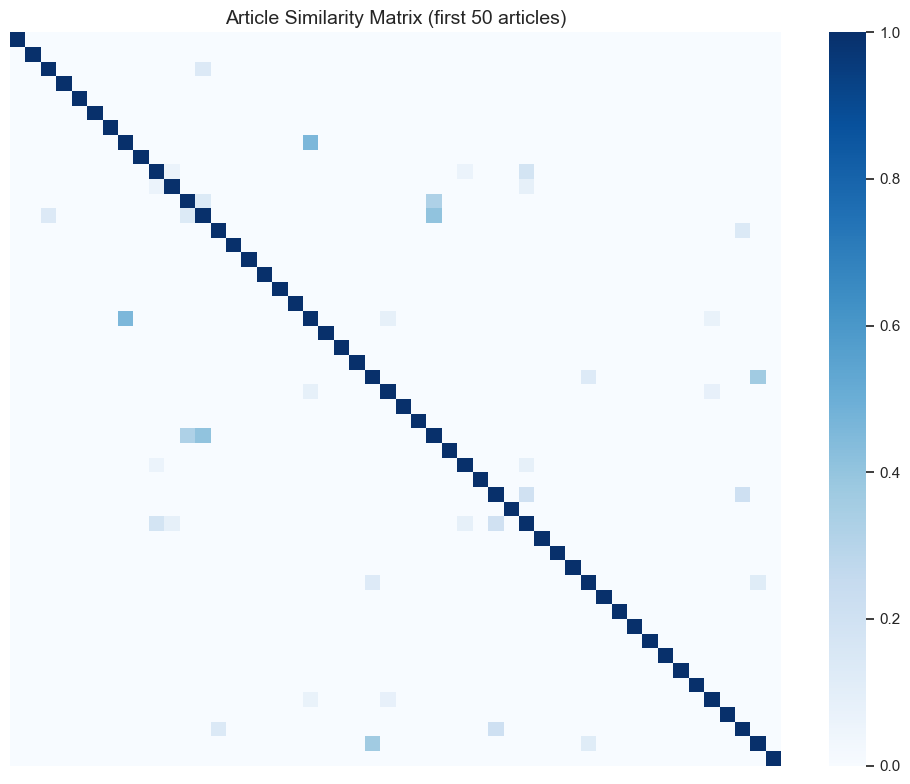

Similarity heatmap saved!


In [10]:
# A heatmap of article similarities gives a nice visual
# of how well our recommender separates topics.
# Articles from the same category should cluster together
# with higher similarity scores between them.

sample_size = 50
sample_indices = list(range(sample_size))
sample_sim = similarity_matrix[:sample_size, :sample_size]
sample_categories = df_articles["category_name"].iloc[:sample_size].tolist()

plt.figure(figsize=(10, 8))
sns.heatmap(
    sample_sim,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False
)
plt.title("Article Similarity Matrix (first 50 articles)", fontsize=14)
plt.tight_layout()
plt.savefig("../data/processed/similarity_heatmap.png")
plt.show()
print("Similarity heatmap saved!")

In [11]:
# We now have a complete re-engagement pipeline.
# The churn model identifies at-risk readers and the
# recommender immediately suggests relevant content
# to bring them back. Together these two components
# mirror the core of what Upscore's Convert and Engage
# products do for publishers like Stern and Heise.

print("=== RECOMMENDATION SUMMARY ===")
print(f"Articles in recommender : {len(df_articles):,}")
print(f"Similarity matrix size  : {similarity_matrix.shape}")
print(f"Recommendation method   : content-based cosine similarity")
print()
print("Next: build the full pipeline and Streamlit dashboard!")

=== RECOMMENDATION SUMMARY ===
Articles in recommender : 5,000
Similarity matrix size  : (5000, 5000)
Recommendation method   : content-based cosine similarity

Next: build the full pipeline and Streamlit dashboard!
